# ¿Vale la pena un inicio aprendido?: una red para las fases de las trampas contra un congelado sin red

**Pregunta:** ¿Hace una red que predice las fases de las trampas que el WGS de fase fija converja más rápido, o un cambio más simple, congelar la fase temprano sin ninguna red, explica toda la ganancia?

- **Nivel:** 4, Métodos propuestos (el inicio aprendido, B3, probado y refutado)
- **Requisitos previos:** notebooks 01 y 02 del tema 01-fourier-optics, y los notebooks 01 a 03 de este tema para saber qué es una red publicada
- **Método ejecutado:** M07 (Gerchberg-Saxton ponderado de fase fija) y la ranura B3 que lo envuelve; la referencia es el WGS-Kim de slmsuite
- **Tiempo de lectura:** unos 55 minutos; el notebook se ejecuta en unos 90 segundos

## Objetivos

El Gerchberg-Saxton ponderado con una fase que se fija tras unas pocas iteraciones es el método práctico para arreglos de cientos o miles de trampas. Su holograma inicial es aleatorio y necesita unas quince iteraciones para dejar las trampas dentro de un uno por ciento entre sí. El producto propuso acortarlo con una red que predice la fase inicial de cada trampa. La propuesta se construyó, se entrenó y se midió, y se rechazó. Ejecutarás la regla sobre el arreglo de 1024 trampas del caso C03 y verás adónde van sus iteraciones, medirás el mejor inicio que cualquier red podría dar, ejecutarás la implementación de referencia de la regla sobre el mismo inicio y luego repetirás el control que explicó la ganancia de la red: el mismo congelado temprano, un inicio aleatorio, sin red. Terminarás sabiendo qué se le atribuyó a la red y qué hizo en realidad.

## Preparación

El entorno de los notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows). Los paquetes que usa este notebook, con sus versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2 slmsuite==0.5.0
```

DinHot no publica ningún paquete propio: sus métodos viven en `data-pipeline/pipeline/` y el notebook los importa por su ruta. slmsuite (MIT) es la implementación de referencia fijada de la regla. La celda siguiente importa las herramientas, silencia la línea de registro por objeto de la referencia e imprime las versiones.

In [1]:
# las herramientas y sus versiones, luego los módulos del pipeline por su ruta y la implementación de referencia fijada
import importlib.metadata as md
import json
import logging
import sys
import warnings
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
logging.disable(logging.INFO)  # la referencia imprime una línea con hora por cada objeto que construye
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.build import setup_of, trapset_of
from pipeline.io.contract import read_cases
from pipeline.model.holo.core import forward, metrics
from pipeline.model.holo.core.geometry import focal_bin_m, input_amplitude
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.traps import Trap, TrapSet
from pipeline.model.holo.core.types import Budget, Target
from pipeline.model.holo.learned import generators
from pipeline.model.holo.learned.evaluation import first_below
from pipeline.model.holo.methods.baseline import m02_random_superposition, m07_phase_fixed_wgs
from pipeline.model.holo.methods.learned import b3_warm_start
from slmsuite.holography.algorithms import SpotHologram

for name in ("numpy", "matplotlib", "slmsuite"):
    print(name, md.version(name))

numpy 2.4.6
matplotlib 3.11.2
slmsuite 0.5.0


## Datos

- Propietario: este repositorio, https://github.com/fsantibanezleal/CEFOP_DinHot.
- Clase de licencia: sintética. El caso C03 lo escribe el producto (32 por 32 trampas, 850 nm, un SLM de 256 por 256 píxeles), las geometrías del control las dibujan los generadores con semilla del producto y el registro de la red rechazada es la medición del propio producto, de modo que no rige ningún conjunto de datos de terceros.
- Archivos leídos: `data/examples/cases.json` (caso C03) y `data/derived/models/warmstart-model-rejected.json`, el registro versionado de la red candidata en 66 geometrías reservadas. No existe archivo de la red: el candidato no se publicó, de modo que el registro se lee como la afirmación que se prueba y nunca se recalcula aquí.

In [2]:
# caso C03, el arreglo grande de 1024 trampas, y el registro versionado del candidato que se probó y se rechazó
records = {rec["case_id"]: rec for rec in read_cases(ROOT / "data" / "examples" / "cases.json")}
rec = records["C03_large_array"]
setup = setup_of(rec)
target = Target.from_traps(trapset_of(rec["target"]["traps"]))
claim = json.loads((ROOT / "data" / "derived" / "models" / "warmstart-model-rejected.json").read_text(encoding="utf-8"))
print(f"{len(target.traps)} trampas, SLM de {setup.n_pix} x {setup.n_pix}, relleno {setup.pad}, semilla {rec['seed']}")
print("registro del candidato:", claim["slot"], "| geometrías reservadas:", claim["metrics"]["held_out_n"])

1024 trampas, SLM de 256 x 256, relleno 2, semilla 20261028
registro del candidato: warmstart-model | geometrías reservadas: 66


## Método

**La regla.** El WGS de fase fija (Kim et al. 2019, https://doi.org/10.1364/OL.44.003178) mantiene un peso $g_m$ por trampa, actualizado en cada iteración a partir de la amplitud $B_i(\mathbf u_m)$ que el holograma hace en la trampa,

$$g_i(\mathbf u_m) = \frac{\langle B_i\rangle_N}{B_i(\mathbf u_m)}\, g_{i-1}(\mathbf u_m), \qquad \mathcal F[A_{i+1} e^{i\phi_{i+1}}] = g_i T\, e^{i\psi_i},$$

donde $T$ es la amplitud objetivo y la fase focal $\psi_i$ sigue al campo durante las primeras $N$ iteraciones y luego queda congelada en $\psi_N$. El artículo usa $N = 12$. El producto llama `n_fix` a $N$. Congelar la fase vuelve casi lineal el problema de los pesos en las iteraciones posteriores, y por eso convergen rápido, y también por eso dejan de mejorar sea cual sea el inicio.

**La propuesta, B3.** Una red equivariante a permutaciones lee la lista de trampas (posiciones en bins focales, profundidad en rangos de Rayleigh, peso) y predice una fase $\theta_m$ por trampa. El holograma inicial es la superposición con esas fases, $\phi^{(0)}_j = \arg \sum_m \sqrt{w_m}\, e^{i(\Delta^m_j + \theta_m)}$, y M07 parte de él. El enunciado de la brecha del producto era que ninguna fuente que leyó inicia WGS con una red. La red se entrenó sin etiquetas, a través de una copia diferenciable de la regla, para aprender un inicio desde el cual M07 converge antes.

**La prueba.** Iteraciones hasta un uno por ciento de desviación estándar relativa de las intensidades de las trampas, $\sigma = 100\,\mathrm{std}(I)/\mathrm{mean}(I)$, en geometrías reservadas, con la eficiencia y la uniformidad finales dentro de un uno por ciento. El criterio pedía una mediana al menos dos veces menor que desde un inicio aleatorio.

El primer paso ejecuta la regla misma sobre el caso C03 desde un inicio aleatorio, una vez con el $N = 12$ del artículo y otra con la fase congelada tras 3 iteraciones. El inicio aleatorio es la superposición con fases de trampa aleatorias, que es lo que dibuja el método del propio motor, y ambas corridas y las siguientes lo toman como inicio explícito para que toda comparación lo comparta.

In [3]:
# WGS de fase fija (M07) sobre las 1024 trampas desde un inicio aleatorio, fase congelada tras 12 y tras 3
start = m02_random_superposition.run(setup, target, budget=Budget(1), rng=Rng(rec["seed"])).phi
runs = {}
for n_fix in (12, 3):
    runs[n_fix] = m07_phase_fixed_wgs.run(setup, target, budget=Budget(20), rng=Rng(1), init=start, n_fix=n_fix)
    last = runs[n_fix].history[-1]
    reached = first_below(runs[n_fix].history, 1.0, 20)
    print(f"congelada tras {n_fix:2d}: 1 por ciento en iteración {reached}, desv. est. final {last['rel_std']:.2f} %, "
          f"eficiencia {last['efficiency']:.3f}, uniformidad {last['uniformity']:.3f}")

congelada tras 12: 1 por ciento en iteración 16, desv. est. final 0.31 %, eficiencia 0.794, uniformidad 0.987
congelada tras  3: 1 por ciento en iteración 21, desv. est. final 6.27 %, eficiencia 0.762, uniformidad 0.757


Con el congelado del artículo la dispersión baja de uno por ciento en la iteración 16 y termina en 0,31 por ciento, con eficiencia 0,794 y uniformidad 0,987. Con el congelado tras 3 iteraciones la corrida nunca llega a uno por ciento en 20 iteraciones: termina en 6,27 por ciento con eficiencia 0,762 y uniformidad 0,757. La figura siguiente dibuja ambas curvas.

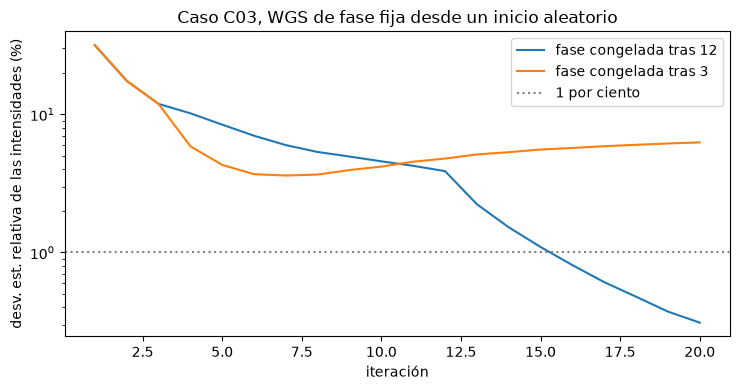

In [4]:
# la dispersión relativa de las 1024 intensidades contra la iteración, para los dos puntos de congelado
fig, ax = plt.subplots(figsize=(7.5, 4))
for n_fix, res in runs.items():
    ax.semilogy(*zip(*[(h["iteration"], h["rel_std"]) for h in res.history]), label=f"fase congelada tras {n_fix}")
ax.axhline(1.0, color="gray", linestyle=":", label="1 por ciento")
ax.set_xlabel("iteración")
ax.set_ylabel("desv. est. relativa de las intensidades (%)")
ax.set_title("Caso C03, WGS de fase fija desde un inicio aleatorio")
ax.legend()
fig.tight_layout()
plt.show()

La curva de doce iteraciones baja despacio y luego cae casi a la mitad en un paso en la iteración 13, la primera iteración tras el congelado, y cruza uno por ciento en la iteración 16; la curva del congelado temprano se aplana tras 6 iteraciones, en cerca de 3,6 por ciento, y deriva hacia arriba hasta cerca de 6,3. La figura muestra que el congelado es la palanca de la velocidad, y que el precio de congelar temprano es un piso. No muestra si un mejor inicio quitaría el piso, que es lo que se supone que da una red. La celda siguiente da a la regla el mejor inicio que existe, el holograma al que convergió una corrida de 40 iteraciones, y la corre con ambos puntos de congelado.

In [5]:
# el mejor inicio posible: el holograma al que convergió una corrida de 40 iteraciones, entregado a la misma regla
long_run = m07_phase_fixed_wgs.run(setup, target, budget=Budget(40), rng=Rng(rec["seed"]), init=start)
oracle = {}
for n_fix in (12, 3):
    oracle[n_fix] = m07_phase_fixed_wgs.run(setup, target, budget=Budget(20), rng=Rng(1), init=long_run.phi,
                                            n_fix=n_fix)
    first = oracle[n_fix].history[0]
    reached = first_below(oracle[n_fix].history, 1.0, 20)
    print(f"inicio convergido, congelada tras {n_fix:2d}: desv. est. {first['rel_std']:.2f} % en la iteración 1, "
          f"1 por ciento en la iteración {reached}")

inicio convergido, congelada tras 12: desv. est. 14.44 % en la iteración 1, 1 por ciento en la iteración 13
inicio convergido, congelada tras  3: desv. est. 14.44 % en la iteración 1, 1 por ciento en la iteración 8


Desde un holograma convergido la primera iteración muestra una dispersión relativa de 14,44 por ciento, no la casi nula que tiene un holograma convergido: la regla reinicia sus pesos en 1 y rehace el trabajo de las primeras iteraciones. Con el congelado del artículo la corrida aún necesita 13 iteraciones para llegar a uno por ciento, tres menos que desde un inicio aleatorio; con el congelado tras 3 llega a uno por ciento en la iteración 8 y sigue bajando. La figura siguiente dibuja los dos inicios para ambos congelados.

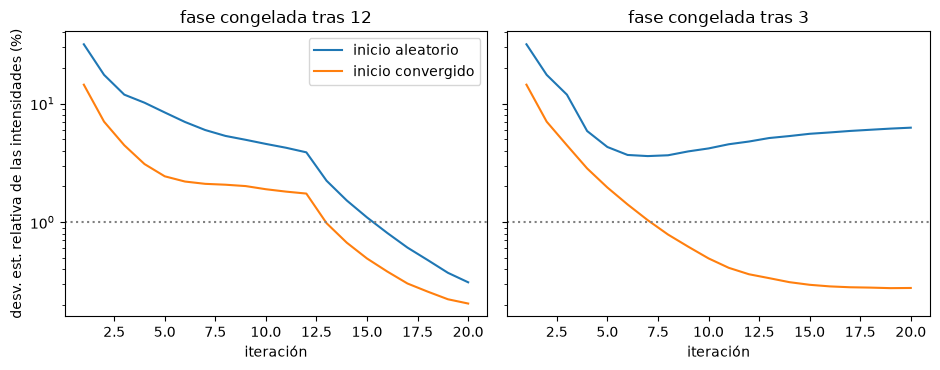

In [6]:
# inicio aleatorio contra inicio convergido, para ambos puntos de congelado
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8), sharey=True)
for ax, n_fix in zip(axes, (12, 3)):
    for label, res in (("inicio aleatorio", runs[n_fix]), ("inicio convergido", oracle[n_fix])):
        ax.semilogy([h["iteration"] for h in res.history], [h["rel_std"] for h in res.history], label=label)
    ax.axhline(1.0, color="gray", linestyle=":")
    ax.set_title(f"fase congelada tras {n_fix}")
    ax.set_xlabel("iteración")
axes[0].set_ylabel("desv. est. relativa de las intensidades (%)")
axes[0].legend()
fig.tight_layout()
plt.show()

A la izquierda, el congelado tras 12, el inicio convergido queda bajo el aleatorio durante las primeras doce iteraciones, y luego ambos bajan tras el congelado, el inicio convergido llegando a uno por ciento tres iteraciones antes y terminando un poco más abajo: un inicio perfecto ahorra unas pocas iteraciones, porque la regla gasta sus primeras doce iteraciones en una actualización de fase que un inicio puede acortar pero no saltar. A la derecha, el congelado tras 3, un buen inicio quita el piso (la curva naranja sigue bajando, hasta cerca de 0,27 por ciento), y uno aleatorio no (la curva azul se detiene cerca de 3,6 por ciento y vuelve a subir hasta cerca de 6,3). Esa es la oportunidad para una red: con un congelado temprano, un inicio suficientemente bueno vale mucho. La figura no dice que una red pueda dar ese inicio a partir de la sola lista de trampas, que es la afirmación que hay que medir.

## Comparación

La implementación de referencia de esta regla es el `WGS-Kim` de slmsuite (Kim et al. 2019, tal como lo implementa slmsuite 0.5.0), que fija la fase del campo lejano tras `fix_phase_iteration` iteraciones. La comparación se hace en igualdad de condiciones: las mismas 1024 trampas sobre la misma grilla con relleno, la misma amplitud del haz de entrada, el mismo inicio aleatorio entregado como fase inicial, la potencia de peso 1 del artículo (el `feedback_exponent` por defecto de slmsuite es 0,8, que el notebook `03-gerchberg-saxton/03-phase-fixed-wgs-against-slmsuite` muestra que es otra variante de la regla) y la misma regla de medida, porque la fase que slmsuite guarda tras cada iteración se puntúa aquí con las métricas de trampa de DinHot. Donde los dos discrepan, la discrepancia es una propiedad de las implementaciones y no de la medida.

In [7]:
# la referencia, WGS-Kim de slmsuite con la potencia de peso 1 del artículo, con las mismas trampas, haz e inicio
# aleatorio; se guarda su fase por iteración
n = setup.n_fft
bins = np.vstack(forward.trap_bins(setup, target.traps)).astype(float)
phases = []


def keep_phase(hologram):
    phases.append(np.asarray(hologram.get_phase()).copy())


holo = SpotHologram(shape=(n, n), spot_vectors=bins, basis="knm", slm_shape=(setup.n_pix,) * 2,
                    amp=input_amplitude(setup))
holo.reset_phase(custom_phase=start)
holo.optimize(method="WGS-Kim", maxiter=20, verbose=False, callback=keep_phase, fix_phase_iteration=12,
              feedback_exponent=1.0)
phases.append(np.asarray(holo.get_phase()).copy())  # el callback corre antes de cada actualización: falta la final
print("fases guardadas:", len(phases), "| forma", phases[0].shape)

fases guardadas: 21 | forma (256, 256)


La referencia guarda el inicio y la fase tras cada una de sus 20 iteraciones, 21 fases de 256 por 256. La celda siguiente puntúa las 20 fases iteradas con el motor e informa la iteración en que cada implementación llega por primera vez a uno por ciento.

In [8]:
# cada iteración de slmsuite se puntúa con las métricas del propio motor, para leer ambos métodos con una misma regla
def spread_of(phi):
    field = forward.trap_fields_from_fft(forward.fft_focal_field(phi, setup), setup, target.traps)
    return metrics.rel_std(metrics.trap_intensities(field))


slm_curve = [spread_of(p) for p in phases[1:]]  # phases[0] es el inicio, phases[k] la fase tras k iteraciones
slm_hist = [{"iteration": k + 1, "rel_std": s} for k, s in enumerate(slm_curve)]
reached = first_below(slm_hist, 1.0, 20)
print(f"slmsuite WGS-Kim: 1 por ciento en la iteración {reached}, desv. est. relativa final {slm_curve[-1]:.2f} %")
print(f"DinHot M07:       1 por ciento en la iteración {first_below(runs[12].history, 1.0, 20)}, "
      f"desv. est. relativa final {runs[12].history[-1]['rel_std']:.2f} %")

slmsuite WGS-Kim: 1 por ciento en la iteración 16, desv. est. relativa final 0.31 %
DinHot M07:       1 por ciento en la iteración 16, desv. est. relativa final 0.31 %


La referencia llega a uno por ciento en la iteración 16 y termina en 0,31 por ciento, y lo mismo la regla de DinHot: el mismo inicio, la misma potencia de peso y el mismo congelado dan la misma corrida, como lo establece la prueba de paridad del producto para el caso C03 (`tests/methods/baseline/test_m07_against_slmsuite.py`). La figura siguiente dibuja ambas.

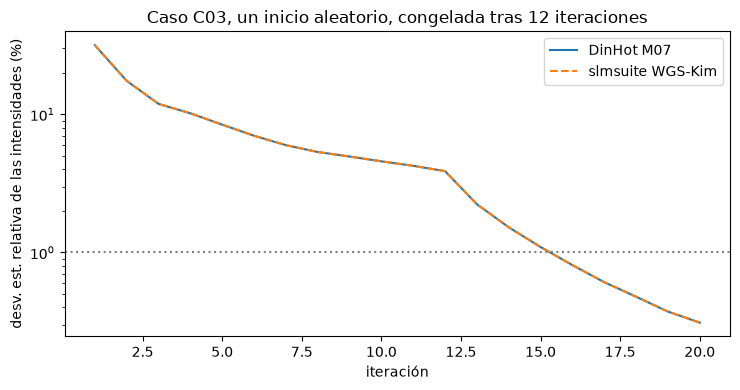

In [9]:
# las dos implementaciones de la misma regla, lado a lado
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.semilogy([h["iteration"] for h in runs[12].history], [h["rel_std"] for h in runs[12].history], label="DinHot M07")
ax.semilogy(range(1, len(slm_curve) + 1), slm_curve, "--", label="slmsuite WGS-Kim")
ax.axhline(1.0, color="gray", linestyle=":")
ax.set_xlabel("iteración")
ax.set_ylabel("desv. est. relativa de las intensidades (%)")
ax.set_title("Caso C03, un inicio aleatorio, congelada tras 12 iteraciones")
ax.legend()
fig.tight_layout()
plt.show()

Las dos curvas quedan una sobre la otra, con la caída lenta y la bajada justo después de la iteración 12. La figura muestra que el comportamiento de la regla no depende de la implementación, así que lo que sigue es una afirmación sobre la regla y no sobre el código de DinHot; no muestra cuál de las dos está más cerca del hardware del artículo. Con la referencia en la mano, la afirmación puede probarse.

## Evidencia

**La afirmación de B3:** una red que predice las fases de las trampas parte WGS de fase fija desde un holograma mejor, de modo que la regla necesita al menos dos veces menos iteraciones hasta uno por ciento en geometrías que la red nunca vio. El registro versionado es la medición del candidato entrenado 6000 pasos (un transformador de conjuntos de 80,8 mil parámetros, un grafo de 339 kilobytes) con el congelado tras 3 iteraciones, contra un inicio aleatorio con el congelado del artículo tras 12. La celda siguiente lee las medianas del registro.

In [10]:
# la afirmación que se probó: las medianas versionadas del candidato entrenado en geometrías reservadas
iters = claim["metrics"]["iterations_to_1pct"]
for arm, label in (("random", "inicio aleatorio, congelada 12"), ("model", "inicio de la red, congelada 3")):
    q = iters[arm]
    print(f"{label}: mediana {q['median']} iteraciones (q1 {q['q1']}, q3 {q['q3']})")
print("razón de medianas:", claim["ratio_random_over_model_median_iterations"], "| el criterio pedía 2")
gap = claim["final_metrics_relative_difference_of_medians"]["efficiency"]
print("la eficiencia final difiere en", round(100 * gap, 1), "por ciento")
ctl = claim["control_without_the_network"]
for arm, (median, _q3) in ctl["median_and_q3_iterations"].items():
    print(f"control del propio registro, 30 geometrías: {arm:15s} mediana {median} iteraciones, "
          f"nunca llega a 1 por ciento {ctl['share_never_reaching_1pct'][arm]:.1%}")

inicio aleatorio, congelada 12: mediana 14.0 iteraciones (q1 13.0, q3 15.0)
inicio de la red, congelada 3: mediana 8.0 iteraciones (q1 5.0, q3 61.0)
razón de medianas: 1.75 | el criterio pedía 2
la eficiencia final difiere en 4.2 por ciento
control del propio registro, 30 geometrías: random_nfix12   mediana 14.0 iteraciones, nunca llega a 1 por ciento 6.7%
control del propio registro, 30 geometrías: random_nfix3    mediana 9.0 iteraciones, nunca llega a 1 por ciento 40.0%
control del propio registro, 30 geometrías: model_nfix3     mediana 16.5 iteraciones, nunca llega a 1 por ciento 46.7%


El candidato llegó a uno por ciento en una mediana de 8 iteraciones contra 14 desde un inicio aleatorio, una razón de 1,75 donde el criterio pedía 2, y su eficiencia final difirió en 4,2 por ciento donde se permitía uno por ciento. El cuartil superior es 61 iteraciones, lo que significa que más de un cuarto de las geometrías nunca llegó a uno por ciento dentro del presupuesto. La comparación tiene un factor de confusión que el registro declara: el brazo de la red congeló tras 3 iteraciones y el brazo aleatorio tras 12. El control del propio registro lo elimina en 30 geometrías, y sus últimas líneas muestran el resultado: con el mismo congelado tras 3, un inicio aleatorio tiene una mediana de 9,0 iteraciones y el inicio de la red 16,5, con 40,0 y 46,7 por ciento de las corridas sin llegar nunca a uno por ciento. Ese control es una medición versionada. El notebook lo repite, en diez geometrías densas bidimensionales (30 a 100 trampas) de los generadores del producto con la óptica de C03 y 64 por 64 píxeles para acortar la corrida, y agrega el congelado intermedio.

In [11]:
# diez geometrías 2D densas de los generadores del producto, con la óptica de C03 y 64 x 64 píxeles, para acortar
small = replace(setup, n_pix=64)
bin_m = focal_bin_m(small)
gen = np.random.default_rng(20261028)
geometries = []
while len(geometries) < 10:
    pts = generators.sample_traps(gen, half_field=56.0, family=str(gen.choice(["grid", "hex", "ring", "random"])))
    if 30 <= len(pts) <= 100:
        traps_g = TrapSet(Trap(i, r[0] * bin_m, r[1] * bin_m, 0.0, r[3]) for i, r in enumerate(pts))
        geometries.append(Target.from_traps(traps_g))
print("trampas por geometría:", [len(g.traps) for g in geometries])

trampas por geometría: [39, 67, 64, 48, 93, 83, 99, 63, 81, 31]


Las geometrías salen de las familias de rejilla, hexagonal, anillo y aleatoria del generador, los arreglos regulares e irregulares con que se entrenó el candidato; ninguna tiene profundidad, porque el congelado temprano se prueba en el plano. La celda siguiente ejecuta tres puntos de congelado en cada geometría con dos semillas, 60 corridas en total, y da a cada brazo el mismo inicio aleatorio para una geometría y semilla.

In [12]:
# tres puntos de congelado por geometría y dos semillas: el mismo inicio aleatorio en cada brazo
arms = {12: [], 6: [], 3: []}
for target_g in geometries:
    for seed in (301, 302):
        for n_fix in arms:
            res = m07_phase_fixed_wgs.run(small, target_g, budget=Budget(20), rng=Rng(seed), n_fix=n_fix)
            last = res.history[-1]
            arms[n_fix].append((first_below(res.history, 1.0, 20), last["efficiency"], last["rel_std"]))
for n_fix, rows_n in arms.items():
    it, eff, spread = (np.array(col) for col in zip(*rows_n))
    print(f"congelada {n_fix:2d}: iter. mediana {np.median(it):4.1f}, nunca llegan a 1 %  {np.mean(it > 20):4.0%}, "
          f"eficiencia final mediana {np.median(eff):.3f}, desv. est. relativa final mediana {np.median(spread):.3f} %")

congelada 12: iter. mediana 13.0, nunca llegan a 1 %   15%, eficiencia final mediana 0.771, desv. est. relativa final mediana 0.062 %
congelada  6: iter. mediana  8.0, nunca llegan a 1 %   25%, eficiencia final mediana 0.756, desv. est. relativa final mediana 0.512 %
congelada  3: iter. mediana  6.0, nunca llegan a 1 %   30%, eficiencia final mediana 0.740, desv. est. relativa final mediana 0.725 %


Con el congelado del artículo tras 12 iteraciones la mediana es 13,0 iteraciones y 15 por ciento de las 20 corridas nunca llegan a uno por ciento dentro de 20 iteraciones. Congelar tras 6 da una mediana de 8,0 y 25 por ciento nunca llega; congelar tras 3 da 6,0, más rápido que la velocidad que mostró la red (8) y que la mediana del control propio del registro (9,0), y 30 por ciento nunca llega. El congelado temprano muestra su costo en el estado final: la eficiencia mediana baja de 0,771 a 0,756 a 0,740 a medida que el congelado se adelanta, cerca de 4 por ciento, que es el 4,2 por ciento que el registro cuenta contra la red, y la dispersión final mediana crece de 0,062 a 0,512 a 0,725 por ciento. La figura siguiente dibuja todas las corridas.

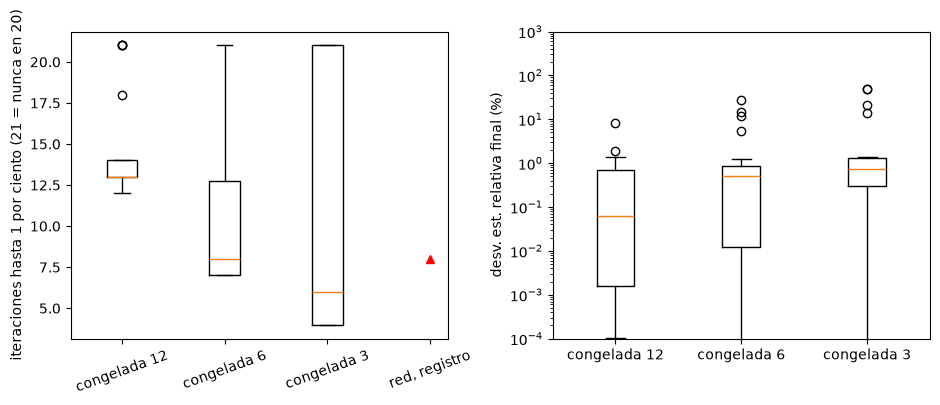

In [13]:
# iteraciones hasta 1 por ciento y dispersión final de cada corrida, por punto de congelado, y el registro
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4))
labels = [f"congelada {n}" for n in arms]
axes[0].boxplot([[r[0] for r in arms[n]] for n in arms], tick_labels=labels, positions=[1, 2, 3])
axes[0].plot([4], [iters["model"]["median"]], "r^")
axes[0].set_xticks([1, 2, 3, 4], labels + ["red, registro"])
axes[0].set_ylabel("iteraciones hasta 1 por ciento (21 = nunca en 20)")
axes[0].tick_params(axis="x", labelrotation=20)
axes[1].boxplot([[r[2] for r in arms[n]] for n in arms], tick_labels=labels)
axes[1].set_yscale("log")
axes[1].set_ylim(1e-4, 1e3)
axes[1].set_ylabel("desv. est. relativa final (%)")
fig.tight_layout()
plt.show()

A la izquierda, las iteraciones hasta uno por ciento bajan con cada congelado más temprano, de una mediana de 13 a 8 a 6, mientras las cajas se ensanchan: la caja del congelado tras 3 va de 4 iteraciones al techo, 21 en este eje significa que no se alcanzó dentro de 20 iteraciones. El triángulo rojo, la mediana registrada de la red, 8, queda dentro de las cajas de los congelados tempranos y sobre la mediana del congelado tras 3, 6,0 aquí. A la derecha, la dispersión final en escala logarítmica sube con el congelado temprano, así que la velocidad se paga con la calidad del estado final. La figura muestra que la velocidad que mostró la red candidata está disponible sin ella, solo con el congelado, y que el congelado cambia corridas fallidas y eficiencia por ella. No muestra que ninguna red pueda ayudar, ya que otro entrenamiento o etiquetas aún podrían dar un inicio que quite el piso, como lo hizo el inicio convergido en la primera parte. La última revisión es el comportamiento del propio producto: B3, llamado sin modelo publicado, debe responder como un inicio aleatorio, y nada en el repositorio puede afirmar que la red existe.

In [14]:
# sin modelo publicado la ranura responde con el inicio aleatorio: B3 y M07 dan exactamente la misma fase
probe = geometries[0]
b3_run = b3_warm_start.run(small, probe, budget=Budget(10), rng=Rng(301))
m07_run = m07_phase_fixed_wgs.run(small, probe, budget=Budget(10), rng=Rng(301), form="point")
same = bool(np.array_equal(b3_run.phi, m07_run.phi))
print("procedencia de B3:", b3_run.meta["provenance"], "| misma fase que M07:", same)
print("existe un grafo warmstart-model publicado:", (ROOT / "models" / "warmstart-model.onnx").exists())

procedencia de B3: baseline | misma fase que M07: True
existe un grafo warmstart-model publicado: False


## Resultados

**Respuesta:** No: la ganancia se explica por un cambio más simple. En geometrías reservadas la red rechazada necesitó una mediana de 8 iteraciones hasta uno por ciento frente a 14 desde un inicio aleatorio (razón 1,75), pero también congeló la fase tras 3 iteraciones donde el brazo aleatorio congeló tras 12. El control sin red, un inicio aleatorio congelado tras 3 iteraciones, necesita una mediana de 6,0 iteraciones en las diez geometrías del notebook, frente a 13,0 con el congelado del artículo, y un congelado tras 6 iteraciones necesita 8,0. El control propio del registro en 30 geometrías da 9,0 para el inicio aleatorio y 16,5 para la red con el mismo congelado, así que la red no agregó nada sobre un inicio aleatorio. El congelado, no el inicio, compra la velocidad, y cuesta convergencia: 30 por ciento de las corridas de congelado temprano aquí nunca llegaron a uno por ciento (40,0 por ciento en el control del registro, 46,7 por ciento para la red) y la eficiencia final mediana bajó de 0,771 a 0,740. El mejor inicio posible no rescata el congelado del artículo, que aún necesita 13 iteraciones desde un holograma convergido en el caso C03, y sí ayuda al congelado temprano, que entonces llega a uno por ciento en la iteración 8. El espacio B3 responde con el inicio aleatorio mientras no haya un modelo publicado, y no existe ningún grafo, que es el estado que registra el producto: B3 se informa como probada y refutada.

Lo que el notebook no muestra: los números de la red por geometría (el registro guarda medianas y cuartiles), geometrías con profundidad, o una red entrenada con etiquetas convergidas. El registro plantea esto como preguntas de diseño para una nueva propuesta, no como ajuste de esta. El control aquí es pequeño, diez geometrías y dos semillas en un SLM de 64 por 64 píxeles; sus medianas quedan bajo las del control del registro, que se midió antes de que la regla se corrigiera para proyectar sin pesos el campo del inicio (2026-10-29), y apuntan en la misma dirección.

## Resumen

Un inicio solo puede ayudar a un método cuyas iteraciones posteriores aún dependen de él. El WGS de fase fija con las doce iteraciones libres del artículo borra la mayor parte de la ventaja de un inicio, y con un congelado temprano es el congelado el que converge rápido y el inicio el que decide si el piso es bajo. Una red que predice fases de trampas a partir de la lista de trampas no dio un inicio suficientemente bueno para bajar el piso, y su aparente aceleración la reprodujo un inicio aleatorio con el mismo congelado y sin red. La implementación de referencia, el WGS-Kim de slmsuite con la potencia de peso del artículo, da la misma corrida que la regla de DinHot desde el mismo inicio, así que la regla y los números no dependen del código de DinHot. El producto, por lo tanto, no entrega ningún modelo de inicio y informa B3 como un negativo medido; la próxima propuesta en esta dirección tendría que partir de etiquetas convergidas o cambiar la regla de congelado, y se juzgaría contra el control que ejecuta este notebook.

## Referencias

- Kim, Kim, Lee y Ahn, "Gerchberg-Saxton algorithm with phase fixing for holographic optical tweezers arrays", Optics Letters 44, 3178 (2019), https://doi.org/10.1364/OL.44.003178.
- Eybposh et al., "DeepCGH: 3D computer-generated holography using deep learning", Optics Express 28, 26636 (2020), https://doi.org/10.1364/OE.399624.
- Ren et al., una red generativa para pinzas ópticas holográficas (2024), https://arxiv.org/abs/2401.06014, el trabajo con que el enunciado de brecha del producto se comparó.
- Di Leonardo, Ianni y Ruocco, "Computer generation of optimal holograms for optical trap arrays", Optics Express 15, 1913 (2007), https://doi.org/10.1364/OE.15.001913.
- slmsuite 0.5.0 (MIT), https://github.com/slmsuite/slmsuite, la implementación de referencia fijada.
- El registro medido del candidato rechazado del producto, `data/derived/models/warmstart-model-rejected.json`.